# Phân cụm khách hàng bằng K-Means — Olist Data Warehouse (Team 7)

**Input:** `main_mart.mart_customer_360` trên MotherDuck (1 dòng / khách có ≥ 1 đơn delivered).
**Output:** schema `ml` trên MotherDuck gồm 3 bảng: `ml.customer_cluster`, `ml.cluster_profile`, `ml.kmeans_model_selection`; 6 hình trong `docs/figures/ml/`.

Notebook này là nguồn duy nhất sinh kết quả phân cụm. Chạy lại toàn bộ notebook sẽ cho cùng một kết quả nhờ `random_state` cố định.

In [1]:
import os
import sys
from datetime import datetime
from pathlib import Path

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from dotenv import load_dotenv
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.preprocessing import StandardScaler

# ---- Cấu hình cố định ----
RANDOM_STATE = 42
FEATURE_SET_VERSION = "v1"
K_RANGE = range(2, 11)          # đánh giá K = 2..10
K_CHOICE_RANGE = (3, 8)         # chỉ chọn K trong 3..8
MIN_CLUSTER_PCT = 2.0           # loại K có cụm nhỏ hơn 2% dân số
SIL_SAMPLE = 10_000             # silhouette tính trên mẫu (O(n^2))
N_INIT = 10
ARI_THRESHOLD = 0.90
INPUT_TABLE = "main_mart.mart_customer_360"
OUT_SCHEMA = "ml"
EXPECTED_ROWS = 93_358

NB_DIR = Path.cwd()
REPO_DIR = NB_DIR.parent if NB_DIR.name == "notebooks" else NB_DIR
FIG_DIR = REPO_DIR / "docs" / "figures" / "ml"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.4f}".format)
sns.set_theme(style="whitegrid")

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("duckdb      :", duckdb.__version__)
print("scikit-learn:", sklearn.__version__)
print("Thư mục hình:", FIG_DIR)

Python      : 3.13.1
pandas      : 3.1.0
duckdb      : 1.5.6
scikit-learn: 1.9.1
Thư mục hình: E:\UEL\Data-Warehouse\docs\figures\ml


## Bước 1 — Đọc dữ liệu và kiểm tra đầu vào
Kết nối MotherDuck bằng token trong `.env`. Không có token hoặc thiếu bảng thì dừng ngay, không dùng dữ liệu thay thế.

In [2]:
load_dotenv(REPO_DIR / ".env")
test_db = os.getenv("ML_TEST_DUCKDB")  # chỉ dùng khi kiểm thử code, để trống khi chạy thật
if test_db:
    con = duckdb.connect(test_db)
    print("[TEST MODE] dùng", test_db)
else:
    token = os.getenv("MOTHERDUCK_TOKEN")
    db_name = os.getenv("MOTHERDUCK_DATABASE", "olist_warehouse")
    if not token:
        raise RuntimeError("Không tìm thấy MOTHERDUCK_TOKEN trong .env")
    con = duckdb.connect(f"md:{db_name}", config={"motherduck_token": token})
    print("Đã kết nối MotherDuck:", con.execute("SELECT current_database()").fetchone()[0])

COLS = ["customer_unique_id", "recency_days", "total_gmv", "total_orders", "is_repeat_customer",
        "avg_review_score", "avg_lead_time_days", "avg_delivery_delay_days",
        "orders_on_time", "orders_late", "latest_state", "segment", "snapshot_date"]
df = con.execute(f"SELECT {', '.join(COLS)} FROM {INPUT_TABLE} ORDER BY customer_unique_id").df()

for c in ["recency_days", "total_gmv", "avg_review_score", "avg_lead_time_days",
          "avg_delivery_delay_days", "total_orders", "is_repeat_customer", "orders_on_time", "orders_late"]:
    df[c] = pd.to_numeric(df[c]).astype(float)

assert len(df) == EXPECTED_ROWS, f"Số dòng {len(df):,} khác {EXPECTED_ROWS:,}"
assert df["customer_unique_id"].is_unique, "customer_unique_id bị trùng"
assert df["snapshot_date"].nunique() == 1, "snapshot_date có nhiều giá trị"
SNAPSHOT_DATE = pd.Timestamp(df["snapshot_date"].iloc[0]).date()
print(f"Số khách: {len(df):,} | snapshot_date: {SNAPSHOT_DATE}")

print("\nThống kê mô tả:")
display(df.describe().T.round(2))
print("Số giá trị NULL mỗi cột:")
display(df.isna().sum().to_frame("n_null").T)

Đã kết nối MotherDuck: olist_warehouse


Số khách: 93,358 | snapshot_date: 2018-08-29

Thống kê mô tả:


,count,mean,min,25%,50%,75%,max,std
recency_days,"93,358.0000",237.4789,0.0000,114.0000,218.0000,346.0000,713.0000,152.5951
total_gmv,"93,358.0000",165.1682,9.5900,63.0100,107.7800,182.5100,"13,664.0800",226.2921
total_orders,"93,358.0000",1.0334,1.0000,1.0000,1.0000,1.0000,15.0000,0.2091
is_repeat_customer,"93,358.0000",0.0300,0.0000,0.0000,0.0000,0.0000,1.0000,0.1706
avg_review_score,"92,755.0000",4.1537,1.0000,4.0000,5.0000,5.0000,5.0000,1.2801
avg_lead_time_days,"93,350.0000",12.5066,0.0000,7.0000,10.0000,16.0000,210.0000,9.5551
avg_delivery_delay_days,"93,350.0000",-11.8483,-147.0000,-17.0000,-12.0000,-7.0000,188.0000,10.1388
orders_on_time,"93,358.0000",0.9495,0.0000,1.0000,1.0000,1.0000,15.0000,0.3419
orders_late,"93,358.0000",0.0838,0.0000,0.0000,0.0000,0.0000,3.0000,0.2793
snapshot_date,93358,2018-08-29 00:00:00,2018-08-29 00:00:00,2018-08-29 00:00:00,2018-08-29 00:00:00,2018-08-29 00:00:00,2018-08-29 00:00:00,NaN


Số giá trị NULL mỗi cột:


,customer_unique_id,recency_days,total_gmv,total_orders,is_repeat_customer,avg_review_score,avg_lead_time_days,avg_delivery_delay_days,orders_on_time,orders_late,latest_state,segment,snapshot_date
n_null,0,0,0,0,0,603,8,8,0,0,0,0,0


## Bước 2 — Xây dựng đặc trưng (feature set v1)

| Đặc trưng | Nguồn | Xử lý |
|---|---|---|
| `f_recency` | `recency_days` | `log1p` |
| `f_monetary` | `total_gmv` | `log1p` |
| `f_review` | `avg_review_score` | NULL → median |
| `f_lead_time` | `avg_lead_time_days` | NULL → median, rồi `log1p` |
| `f_delay` | `avg_delivery_delay_days` | NULL → median, rồi cắt về [P1, P99] (không log vì có giá trị âm) |

Sau đó chuẩn hóa bằng `StandardScaler`.

**Vì sao không đưa `total_orders` / `is_repeat_customer` vào mô hình:** 97% khách chỉ có 1 đơn. Sau khi chuẩn hóa, 3% khách mua lặp có z-score rất lớn và sẽ tự tách thành một cụm riêng, lấn át các chiều còn lại (kiểm chứng ở Bước 6). Biến này chỉ dùng để mô tả cụm (`repeat_rate`).

Tham số tiền xử lý:
  median_review     : 5.00
  median_lead_time  : 10.00
  median_delay      : -12.00
  delay_p1          : -35.71
  delay_p99         : 18.00


,f_recency,f_monetary,f_review,f_lead_time,f_delay
f_recency,1.0000,-0.0160,-0.0200,0.1730,-0.1070
f_monetary,-0.0160,1.0000,-0.0400,0.1440,-0.0620
f_review,-0.0200,-0.0400,1.0000,-0.2330,-0.1750
f_lead_time,0.1730,0.1440,-0.2330,1.0000,0.3130
f_delay,-0.1070,-0.0620,-0.1750,0.3130,1.0000


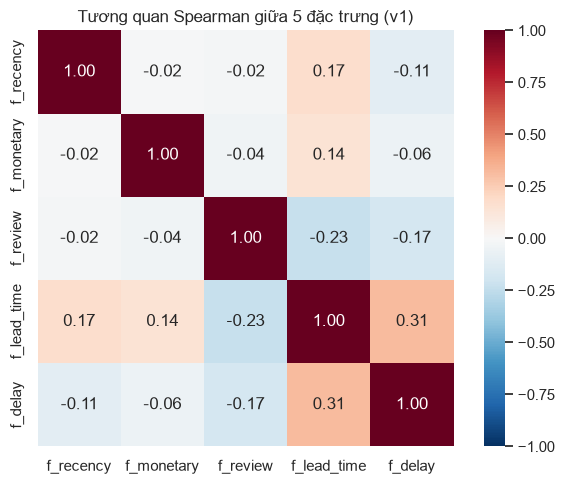

In [3]:
prep = {
    "median_review": float(df["avg_review_score"].median()),
    "median_lead_time": float(df["avg_lead_time_days"].median()),
    "median_delay": float(df["avg_delivery_delay_days"].median()),
}
delay_filled = df["avg_delivery_delay_days"].fillna(prep["median_delay"])
prep["delay_p1"] = float(delay_filled.quantile(0.01))
prep["delay_p99"] = float(delay_filled.quantile(0.99))

feat = pd.DataFrame({
    "f_recency": np.log1p(df["recency_days"]),
    "f_monetary": np.log1p(df["total_gmv"]),
    "f_review": df["avg_review_score"].fillna(prep["median_review"]),
    "f_lead_time": np.log1p(df["avg_lead_time_days"].fillna(prep["median_lead_time"])),
    "f_delay": delay_filled.clip(prep["delay_p1"], prep["delay_p99"]),
})
FEATURES = list(feat.columns)
assert feat.notna().all().all()

scaler = StandardScaler()
X = scaler.fit_transform(feat.values)

print("Tham số tiền xử lý:")
for k, v in prep.items():
    print(f"  {k:<18}: {v:.2f}")

corr = feat.corr(method="spearman")
display(corr.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Tương quan Spearman giữa 5 đặc trưng (v1)")
plt.tight_layout()
fig.savefig(FIG_DIR / "01_feature_correlation.png", dpi=150)
plt.show()

## Bước 3 — Chọn số cụm K
Với K = 2..10: inertia, silhouette (mẫu 10,000), Davies-Bouldin, Calinski-Harabasz và tỷ lệ cụm nhỏ nhất.

**Luật chọn K:** chỉ xét K = 3..8; loại K có cụm nhỏ nhất < 2% dân số; chọn K có silhouette cao nhất; nếu nhiều K chênh silhouette < 0.01 so với K tốt nhất thì chọn K nhỏ nhất (ưu tiên mô hình đơn giản, dễ diễn giải).

Bảng đánh giá K:


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct
0,2,"371,573.7820",0.2756,1.6015,"23,923.0494",22.0035
1,3,"308,680.7969",0.2409,1.5427,"23,908.7766",16.6274
2,4,"267,739.4705",0.1981,1.4971,"23,134.9202",14.6329
3,5,"238,631.2660",0.2085,1.4075,"22,314.2266",8.7298
4,6,"212,098.3124",0.2065,1.2821,"22,419.8821",6.0498
5,7,"197,251.9329",0.2051,1.3262,"21,260.3156",6.0541
6,8,"185,409.1439",0.1952,1.3315,"20,238.6575",5.4628
7,9,"175,895.2855",0.1892,1.3204,"19,297.6403",5.4618
8,10,"169,260.9045",0.1796,1.3488,"18,232.1678",5.2797


Ứng viên hợp lệ (sắp theo silhouette):


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct
0,3,"308,680.7969",0.2409,1.5427,"23,908.7766",16.6274
1,5,"238,631.2660",0.2085,1.4075,"22,314.2266",8.7298
2,6,"212,098.3124",0.2065,1.2821,"22,419.8821",6.0498
3,7,"197,251.9329",0.2051,1.3262,"21,260.3156",6.0541
4,4,"267,739.4705",0.1981,1.4971,"23,134.9202",14.6329
5,8,"185,409.1439",0.1952,1.3315,"20,238.6575",5.4628


Silhouette cao nhất = 0.2409; các K trong vùng chênh < 0.01: [3]
AUTO_K = 3 | FINAL_K = 3


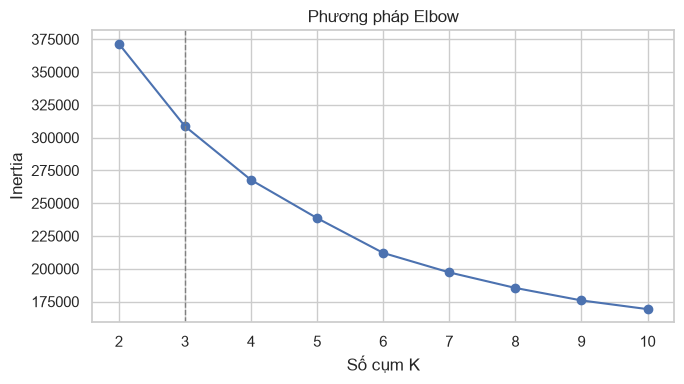

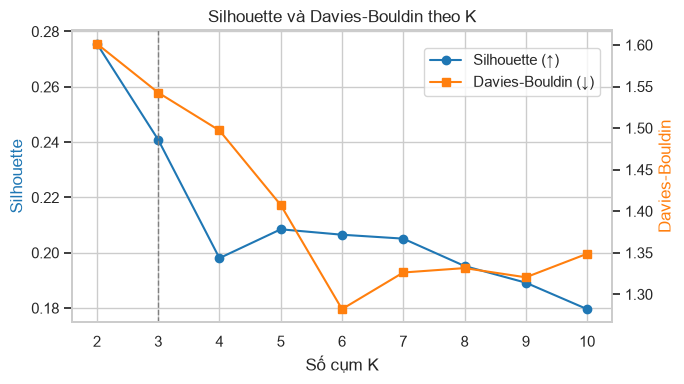

In [4]:
records = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=RANDOM_STATE)
    lab = km.fit_predict(X)
    sizes = np.bincount(lab, minlength=k)
    records.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(X, lab, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE),
        "davies_bouldin": davies_bouldin_score(X, lab),
        "calinski_harabasz": calinski_harabasz_score(X, lab),
        "min_cluster_pct": 100 * sizes.min() / len(lab),
    })
k_eval = pd.DataFrame(records)
print("Bảng đánh giá K:")
display(k_eval.round(4))

cand = k_eval[k_eval["k"].between(*K_CHOICE_RANGE) & (k_eval["min_cluster_pct"] >= MIN_CLUSTER_PCT)]
cand = cand.sort_values("silhouette", ascending=False).reset_index(drop=True)
best_sil = cand.loc[0, "silhouette"]
close = cand[(best_sil - cand["silhouette"]) < 0.01]
AUTO_K = int(close["k"].min())
FINAL_K_OVERRIDE = None
FINAL_K = FINAL_K_OVERRIDE if FINAL_K_OVERRIDE is not None else AUTO_K

print("Ứng viên hợp lệ (sắp theo silhouette):")
display(cand.round(4))
print(f"Silhouette cao nhất = {best_sil:.4f}; các K trong vùng chênh < 0.01: {close['k'].tolist()}")
print(f"AUTO_K = {AUTO_K} | FINAL_K = {FINAL_K}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_eval["k"], k_eval["inertia"], marker="o")
ax.axvline(FINAL_K, color="grey", ls="--", lw=1)
ax.set(xlabel="Số cụm K", ylabel="Inertia", title="Phương pháp Elbow")
plt.tight_layout(); fig.savefig(FIG_DIR / "02_elbow.png", dpi=150); plt.show()

fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(k_eval["k"], k_eval["silhouette"], marker="o", color="tab:blue", label="Silhouette (↑)")
ax1.set_xlabel("Số cụm K"); ax1.set_ylabel("Silhouette", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(k_eval["k"], k_eval["davies_bouldin"], marker="s", color="tab:orange", label="Davies-Bouldin (↓)")
ax2.set_ylabel("Davies-Bouldin", color="tab:orange"); ax2.grid(False)
ax1.axvline(FINAL_K, color="grey", ls="--", lw=1)
ax1.set_title("Silhouette và Davies-Bouldin theo K")
fig.legend(loc="upper right", bbox_to_anchor=(0.88, 0.88))
plt.tight_layout(); fig.savefig(FIG_DIR / "03_silhouette_db.png", dpi=150); plt.show()

## Bước 4 — Mô hình cuối và kiểm tra độ ổn định
Huấn luyện với `FINAL_K`, so sánh nhãn với 5 seed khác bằng Adjusted Rand Index (đạt khi trung bình ≥ 0.90). Sau đó đánh số lại cụm theo median GMV giảm dần (cụm 1 = chi tiêu cao nhất) để kết quả tất định.

In [5]:
final_km = KMeans(n_clusters=FINAL_K, n_init=N_INIT, random_state=RANDOM_STATE)
raw_labels = final_km.fit_predict(X)
dist = np.linalg.norm(X - final_km.cluster_centers_[raw_labels], axis=1)

ari = pd.DataFrame({
    "seed": s,
    "ari_vs_seed_42": adjusted_rand_score(
        raw_labels, KMeans(n_clusters=FINAL_K, n_init=N_INIT, random_state=s).fit_predict(X)),
} for s in [0, 1, 2, 3, 4])
display(ari.round(4))
MEAN_ARI = ari["ari_vs_seed_42"].mean()
print(f"Mean ARI = {MEAN_ARI:.4f} ->", "ỔN ĐỊNH" if MEAN_ARI >= ARI_THRESHOLD else "CẢNH BÁO: dưới ngưỡng 0.90")

order = (pd.Series(df["total_gmv"].values).groupby(raw_labels).median()
         .sort_values(ascending=False).index.tolist())
remap = {old: new for new, old in enumerate(order, start=1)}
df["cluster_id"] = pd.Series(raw_labels).map(remap).values
df["distance_to_centroid"] = dist
print("Kích thước cụm:")
display(df["cluster_id"].value_counts().sort_index().to_frame("n_customers"))

,seed,ari_vs_seed_42
0,0,0.9978
1,1,0.9729
2,2,0.9729
3,3,0.9881
4,4,0.9991


Mean ARI = 0.9862 -> ỔN ĐỊNH
Kích thước cụm:


,n_customers
cluster_id,
1,15523
2,56690
3,21145


## Bước 5 — Chân dung cụm
Nhãn `cluster_label` là nhãn mô tả tự động (so median của cụm với median toàn bộ khách): Recency gần đây/lâu rồi, chi cao/thấp, hài lòng (review ≥ 4.0) hay không. Tên nghiệp vụ đặt trong báo cáo.

Median toàn bộ: recency = 218 ngày | GMV = 107.78 BRL | review TB = 4.15 | late rate = 0.0811


,cluster_id,n_customers,pct_customers,sum_gmv,pct_gmv,median_recency_days,median_total_gmv,mean_total_gmv,repeat_rate,avg_review_score,median_lead_time_days,avg_delivery_delay_days,late_order_rate,top_state,pct_top_state,cluster_label
0,1,15523,16.6270,"3,067,611.6000",19.8940,218.0000,125.8700,197.6170,0.0270,1.9400,21.0000,-2.2070,0.3870,SP,30.2580,C1 · Lâu rồi · Chi cao · Không hài lòng
1,2,56690,60.7230,"9,248,487.0900",59.9780,278.0000,107.0150,163.1410,0.0310,4.6280,11.0000,-14.1500,0.0180,SP,39.7510,C2 · Lâu rồi · Chi thấp · Hài lòng
2,3,21145,22.6490,"3,103,675.0600",20.1280,54.0000,97.4300,146.7810,0.0300,4.5070,6.0000,-12.7540,0.0280,SP,56.3630,C3 · Gần đây · Chi thấp · Hài lòng


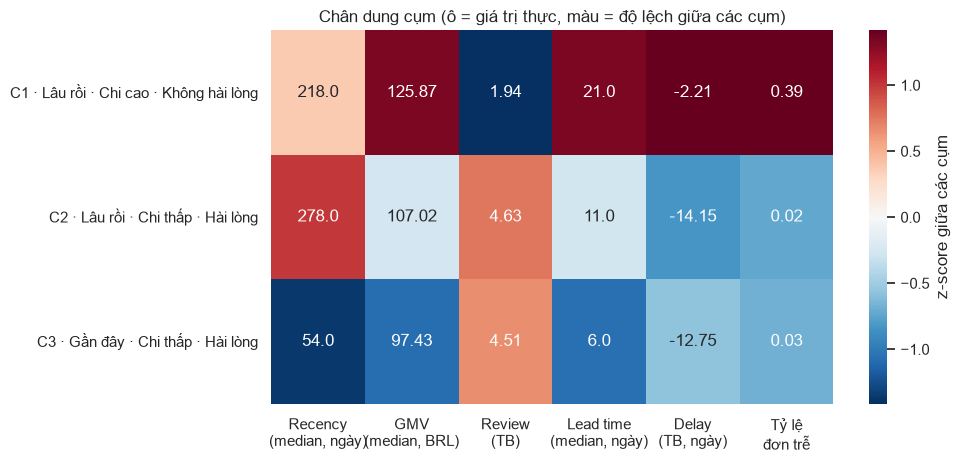

In [6]:
pop_med_r = df["recency_days"].median()
pop_med_m = df["total_gmv"].median()
total_gmv_all = df["total_gmv"].sum()

def top_state(s):
    vc = s.value_counts()
    return pd.Series({"top_state": vc.index[0], "pct_top_state": 100 * vc.iloc[0] / vc.sum()})

g = df.groupby("cluster_id")
profile = pd.DataFrame({
    "n_customers": g.size(),
    "pct_customers": 100 * g.size() / len(df),
    "sum_gmv": g["total_gmv"].sum(),
    "pct_gmv": 100 * g["total_gmv"].sum() / total_gmv_all,
    "median_recency_days": g["recency_days"].median(),
    "median_total_gmv": g["total_gmv"].median(),
    "mean_total_gmv": g["total_gmv"].mean(),
    "repeat_rate": g["is_repeat_customer"].mean(),
    "avg_review_score": g["avg_review_score"].mean(),
    "median_lead_time_days": g["avg_lead_time_days"].median(),
    "avg_delivery_delay_days": g["avg_delivery_delay_days"].mean(),
    "late_order_rate": g["orders_late"].sum() / (g["orders_on_time"].sum() + g["orders_late"].sum()),
}).join(g["latest_state"].apply(top_state).unstack())
profile["pct_top_state"] = profile["pct_top_state"].astype(float)

def make_label(cid, row):
    r = "Gần đây" if row["median_recency_days"] < pop_med_r else "Lâu rồi"
    m = "Chi cao" if row["median_total_gmv"] >= pop_med_m else "Chi thấp"
    e = "Hài lòng" if row["avg_review_score"] >= 4.0 else "Không hài lòng"
    return f"C{cid} · {r} · {m} · {e}"

profile["cluster_label"] = [make_label(cid, row) for cid, row in profile.iterrows()]
profile = profile.reset_index()
df["cluster_label"] = df["cluster_id"].map(dict(zip(profile["cluster_id"], profile["cluster_label"])))

print(f"Median toàn bộ: recency = {pop_med_r:.0f} ngày | GMV = {pop_med_m:.2f} BRL | "
      f"review TB = {df['avg_review_score'].mean():.2f} | "
      f"late rate = {df['orders_late'].sum() / (df['orders_on_time'].sum() + df['orders_late'].sum()):.4f}")
display(profile.round(3))

# Heatmap: z-score của chỉ số đại diện từng cụm, ghi giá trị thực trong ô
hm_cols = {"median_recency_days": "Recency\n(median, ngày)", "median_total_gmv": "GMV\n(median, BRL)",
           "avg_review_score": "Review\n(TB)", "median_lead_time_days": "Lead time\n(median, ngày)",
           "avg_delivery_delay_days": "Delay\n(TB, ngày)", "late_order_rate": "Tỷ lệ\nđơn trễ"}
hm = profile.set_index("cluster_label")[list(hm_cols)].rename(columns=hm_cols)
hz = (hm - hm.mean()) / hm.std(ddof=0).replace(0, 1)
fig, ax = plt.subplots(figsize=(10, 1.1 * FINAL_K + 1.5))
sns.heatmap(hz, annot=hm.round(2), fmt="", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "z-score giữa các cụm"})
ax.set(title="Chân dung cụm (ô = giá trị thực, màu = độ lệch giữa các cụm)", xlabel="", ylabel="")
plt.xticks(rotation=0)
plt.tight_layout(); fig.savefig(FIG_DIR / "04_cluster_profile_heatmap.png", dpi=150); plt.show()

### Trực quan PCA và đối chiếu với phân khúc RFM

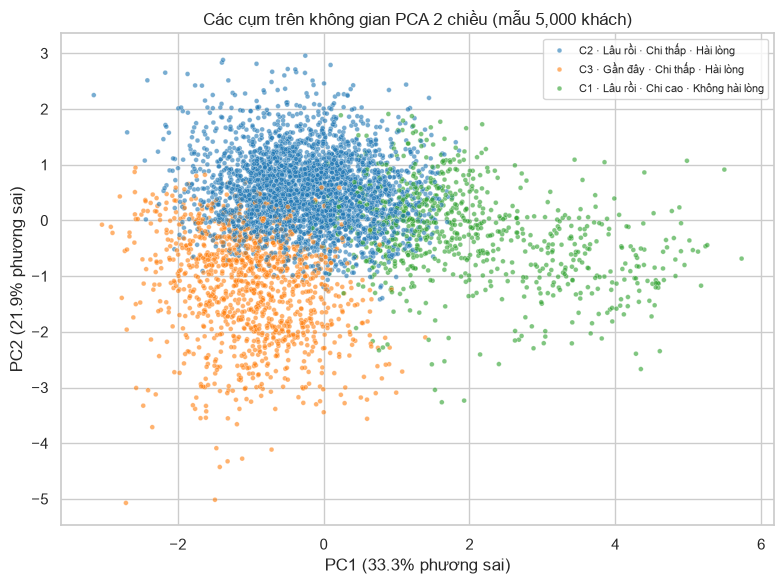

Hệ số tải PCA:


,PC1,PC2
f_recency,0.1720,0.7690
f_monetary,0.1400,0.3950
f_review,-0.5090,0.1470
f_lead_time,0.6260,0.2020
f_delay,0.5480,-0.4360


segment,Khách hàng có nguy cơ rời bỏ,Khách hàng giá trị cao,Khách hàng mua thường xuyên,Khách hàng mới / tiềm năng,Khách hàng phổ thông
cluster_label,,,,,
C1 · Lâu rồi · Chi cao · Không hài lòng,17.5000,16.7000,1.0000,16.1000,48.7000
C2 · Lâu rồi · Chi thấp · Hài lòng,21.3000,9.5000,0.9000,10.7000,57.5000
C3 · Gần đây · Chi thấp · Hài lòng,0.0000,34.9000,0.6000,62.2000,2.3000


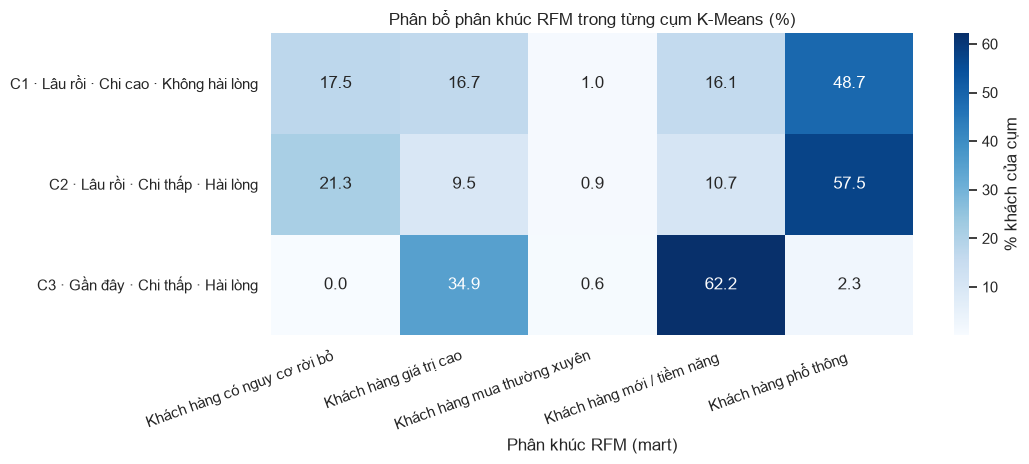

In [7]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Xp = pca.fit_transform(X)
idx = np.random.RandomState(RANDOM_STATE).choice(len(df), 5000, replace=False)
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=Xp[idx, 0], y=Xp[idx, 1], hue=df["cluster_label"].values[idx], s=12, alpha=0.6, ax=ax, palette="tab10")
ev = pca.explained_variance_ratio_ * 100
ax.set(xlabel=f"PC1 ({ev[0]:.1f}% phương sai)", ylabel=f"PC2 ({ev[1]:.1f}% phương sai)",
       title="Các cụm trên không gian PCA 2 chiều (mẫu 5,000 khách)")
ax.legend(fontsize=8, loc="best")
plt.tight_layout(); fig.savefig(FIG_DIR / "05_pca_scatter.png", dpi=150); plt.show()
print("Hệ số tải PCA:")
display(pd.DataFrame(pca.components_.T, index=FEATURES, columns=["PC1", "PC2"]).round(3))

ct = pd.crosstab(df["cluster_label"], df["segment"], normalize="index") * 100
display(ct.round(1))
fig, ax = plt.subplots(figsize=(11, 1.1 * FINAL_K + 1.5))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", ax=ax, cbar_kws={"label": "% khách của cụm"})
ax.set(title="Phân bổ phân khúc RFM trong từng cụm K-Means (%)", xlabel="Phân khúc RFM (mart)", ylabel="")
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); fig.savefig(FIG_DIR / "06_cluster_vs_rfm_segment.png", dpi=150); plt.show()

## Bước 6 — Phân tích độ nhạy: thêm `is_repeat_customer`
Huấn luyện lại với 5 đặc trưng + `is_repeat_customer` (chuẩn hóa), cùng K, để kiểm chứng quyết định loại biến này. Kết quả không ghi ra MotherDuck.

In [8]:
X_rep = StandardScaler().fit_transform(np.column_stack([feat.values, df["is_repeat_customer"].values]))
lab_rep = KMeans(n_clusters=FINAL_K, n_init=N_INIT, random_state=RANDOM_STATE).fit_predict(X_rep)
sil_v1 = silhouette_score(X, raw_labels, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE)
sil_rep = silhouette_score(X_rep, lab_rep, sample_size=SIL_SAMPLE, random_state=RANDOM_STATE)
sens = (pd.DataFrame({"cluster": lab_rep, "is_repeat": df["is_repeat_customer"].values})
        .groupby("cluster").agg(n_customers=("is_repeat", "size"), repeat_rate=("is_repeat", "mean")))
sens["pct_customers"] = 100 * sens["n_customers"] / len(df)
display(sens.round(4))
print(f"Silhouette v1 = {sil_v1:.4f} | v1_plus_repeat = {sil_rep:.4f}")
print(f"ARI(v1, v1_plus_repeat) = {adjusted_rand_score(raw_labels, lab_rep):.4f}")
print(f"Số cụm có repeat_rate = 1.0: {(sens['repeat_rate'] == 1.0).sum()} | "
      f"số cụm có repeat_rate = 0.0: {(sens['repeat_rate'] == 0.0).sum()}")

,n_customers,repeat_rate,pct_customers
cluster,,,
0,70559,0.0000,75.5790
1,2801,1.0000,3.0003
2,19998,0.0000,21.4208


Silhouette v1 = 0.2409 | v1_plus_repeat = 0.2868
ARI(v1, v1_plus_repeat) = 0.3592
Số cụm có repeat_rate = 1.0: 1 | số cụm có repeat_rate = 0.0: 2


## Bước 7 — Ghi kết quả về MotherDuck (schema `ml`)

In [9]:
MODEL_RUN_TS = pd.Timestamp(datetime.now().replace(microsecond=0))

out_customer = pd.DataFrame({
    "customer_unique_id": df["customer_unique_id"],
    "cluster_id": df["cluster_id"].astype("int32"),
    "cluster_label": df["cluster_label"],
    "distance_to_centroid": df["distance_to_centroid"].astype(float),
    "k": np.int32(FINAL_K),
    "feature_set_version": FEATURE_SET_VERSION,
    "snapshot_date": pd.Timestamp(SNAPSHOT_DATE),
    "model_run_ts": MODEL_RUN_TS,
})
out_profile = profile[["cluster_id", "cluster_label", "n_customers", "pct_customers", "sum_gmv", "pct_gmv",
                       "median_recency_days", "median_total_gmv", "mean_total_gmv", "repeat_rate",
                       "avg_review_score", "median_lead_time_days", "avg_delivery_delay_days",
                       "late_order_rate", "top_state", "pct_top_state"]].copy()
out_profile["k"] = FINAL_K
out_profile["feature_set_version"] = FEATURE_SET_VERSION
out_profile["model_run_ts"] = MODEL_RUN_TS
out_sel = k_eval.copy()
out_sel["is_selected"] = out_sel["k"] == FINAL_K
out_sel["feature_set_version"] = FEATURE_SET_VERSION
out_sel["model_run_ts"] = MODEL_RUN_TS

con.execute(f"CREATE SCHEMA IF NOT EXISTS {OUT_SCHEMA}")
for name, frame, cast in [
    ("customer_cluster", out_customer,
     "customer_unique_id, CAST(cluster_id AS INTEGER) AS cluster_id, cluster_label, distance_to_centroid, "
     "CAST(k AS INTEGER) AS k, feature_set_version, CAST(snapshot_date AS DATE) AS snapshot_date, "
     "CAST(model_run_ts AS TIMESTAMP) AS model_run_ts"),
    ("cluster_profile", out_profile,
     "* REPLACE (CAST(cluster_id AS INTEGER) AS cluster_id, CAST(n_customers AS INTEGER) AS n_customers, "
     "CAST(k AS INTEGER) AS k, CAST(model_run_ts AS TIMESTAMP) AS model_run_ts)"),
    ("kmeans_model_selection", out_sel,
     "* REPLACE (CAST(k AS INTEGER) AS k, CAST(model_run_ts AS TIMESTAMP) AS model_run_ts)"),
]:
    con.register("tmp_df", frame)
    con.execute(f"CREATE OR REPLACE TABLE {OUT_SCHEMA}.{name} AS SELECT {cast} FROM tmp_df")
    con.unregister("tmp_df")
    print(f"Đã ghi {OUT_SCHEMA}.{name}: {len(frame):,} dòng")

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Đã ghi ml.customer_cluster: 93,358 dòng


Đã ghi ml.cluster_profile: 3 dòng


Đã ghi ml.kmeans_model_selection: 9 dòng


## Bước 8 — Đọc lại từ MotherDuck và kiểm tra

In [10]:
sel_db = con.execute(f"SELECT * FROM {OUT_SCHEMA}.kmeans_model_selection ORDER BY k").df()
prof_db = con.execute(f"SELECT * FROM {OUT_SCHEMA}.cluster_profile ORDER BY cluster_id").df()
cc_db = con.execute(f"""
    SELECT k, feature_set_version, COUNT(*) AS n, COUNT(DISTINCT customer_unique_id) AS n_unique,
           COUNT(DISTINCT cluster_id) AS n_clusters, MIN(cluster_id) AS min_id, MAX(cluster_id) AS max_id,
           MIN(model_run_ts) AS ts_min, MAX(model_run_ts) AS ts_max
    FROM {OUT_SCHEMA}.customer_cluster GROUP BY 1, 2""").df()
display(sel_db); display(prof_db); display(cc_db)

assert len(cc_db) == 1
r = cc_db.iloc[0]
assert r["n"] == EXPECTED_ROWS and r["n_unique"] == EXPECTED_ROWS
assert r["n_clusters"] == FINAL_K and r["min_id"] == 1 and r["max_id"] == FINAL_K
assert r["ts_min"] == r["ts_max"]
assert prof_db["n_customers"].sum() == EXPECTED_ROWS
assert abs(prof_db["pct_gmv"].sum() - 100) < 0.01
assert sel_db["is_selected"].sum() == 1
print("Tất cả kiểm tra đạt.")

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct,is_selected,feature_set_version,model_run_ts
0,2,"371,573.7820",0.2756,1.6015,"23,923.0494",22.0035,False,v1,2026-11-03 08:39:35
1,3,"308,680.7969",0.2409,1.5427,"23,908.7766",16.6274,True,v1,2026-11-03 08:39:35
2,4,"267,739.4705",0.1981,1.4971,"23,134.9202",14.6329,False,v1,2026-11-03 08:39:35
3,5,"238,631.2660",0.2085,1.4075,"22,314.2266",8.7298,False,v1,2026-11-03 08:39:35
4,6,"212,098.3124",0.2065,1.2821,"22,419.8821",6.0498,False,v1,2026-11-03 08:39:35
5,7,"197,251.9329",0.2051,1.3262,"21,260.3156",6.0541,False,v1,2026-11-03 08:39:35
6,8,"185,409.1439",0.1952,1.3315,"20,238.6575",5.4628,False,v1,2026-11-03 08:39:35
7,9,"175,895.2855",0.1892,1.3204,"19,297.6403",5.4618,False,v1,2026-11-03 08:39:35
8,10,"169,260.9045",0.1796,1.3488,"18,232.1678",5.2797,False,v1,2026-11-03 08:39:35


,cluster_id,cluster_label,n_customers,pct_customers,sum_gmv,pct_gmv,median_recency_days,median_total_gmv,mean_total_gmv,repeat_rate,avg_review_score,median_lead_time_days,avg_delivery_delay_days,late_order_rate,top_state,pct_top_state,k,feature_set_version,model_run_ts
0,1,C1 · Lâu rồi · Chi cao · Không hài lòng,15523,16.6274,"3,067,611.6000",19.8940,218.0000,125.8700,197.6172,0.0272,1.9398,21.0000,-2.2074,0.3865,SP,30.2583,3,v1,2026-11-03 08:39:35
1,2,C2 · Lâu rồi · Chi thấp · Hài lòng,56690,60.7232,"9,248,487.0900",59.9781,278.0000,107.0150,163.1414,0.0309,4.6276,11.0000,-14.1503,0.0176,SP,39.7513,3,v1,2026-11-03 08:39:35
2,3,C3 · Gần đây · Chi thấp · Hài lòng,21145,22.6494,"3,103,675.0600",20.1279,54.0000,97.4300,146.7806,0.0297,4.5067,6.0000,-12.7539,0.0281,SP,56.3632,3,v1,2026-11-03 08:39:35


,k,feature_set_version,n,n_unique,n_clusters,min_id,max_id,ts_min,ts_max
0,3,v1,93358,93358,3,1,3,2026-11-03 08:39:35,2026-11-03 08:39:35


Tất cả kiểm tra đạt.


## Tóm tắt

In [11]:
sel_row = k_eval.set_index("k").loc[FINAL_K]
print(f"K được chọn          : {FINAL_K} (AUTO_K = {AUTO_K}, override = {FINAL_K_OVERRIDE})")
print(f"Silhouette (mẫu 10k) : {sel_row['silhouette']:.4f}")
print(f"Davies-Bouldin       : {sel_row['davies_bouldin']:.4f}")
print(f"Mean ARI (5 seed)    : {MEAN_ARI:.4f}")
print(f"model_run_ts         : {MODEL_RUN_TS}")
print("Hình đã lưu:", sorted(p.name for p in FIG_DIR.glob("*.png")))
con.close()

K được chọn          : 3 (AUTO_K = 3, override = None)
Silhouette (mẫu 10k) : 0.2409
Davies-Bouldin       : 1.5427
Mean ARI (5 seed)    : 0.9862
model_run_ts         : 2026-11-03 08:39:35
Hình đã lưu: ['01_feature_correlation.png', '02_elbow.png', '03_silhouette_db.png', '04_cluster_profile_heatmap.png', '05_pca_scatter.png', '06_cluster_vs_rfm_segment.png']
